# Clasificación de dígitos 0-9 (MNIST)

**Materia:** Inteligencia Artificial
**Profesor:** José Mario Ríos Félix
**Alumno:** Jose de Jesus Quintero Noris
**No. de control:** 23170288

En este cuaderno se entrena una red neuronal para reconocer dígitos escritos a mano con el dataset **MNIST**, y el modelo ya entrenado se guarda en un archivo (`modelo_digitos.keras`). Ese archivo se carga después en una aplicación aparte (`tarea7_mnist_probar.py`) para probarlo en tiempo real dibujando con el mouse.

Para ejecutarlo en Google Colab: menú **Entorno de ejecución > Ejecutar todo**.

## 1. Librerías

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Semilla fija para que los resultados se parezcan entre ejecuciones
keras.utils.set_random_seed(7)
print('Keras', keras.__version__)

Keras 3.15.1


## 2. Cargar el dataset

MNIST son imágenes de dígitos escritos a mano, en blanco y negro y de 28 × 28 píxeles. Trae 60,000 imágenes para entrenar y 10,000 aparte para probar el modelo con datos que nunca vio.

Entrenamiento: (60000, 28, 28) (60000,)
Prueba: (10000, 28, 28) (10000,)
Valores de los píxeles: de 0 a 255
Imágenes de entrenamiento por dígito: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


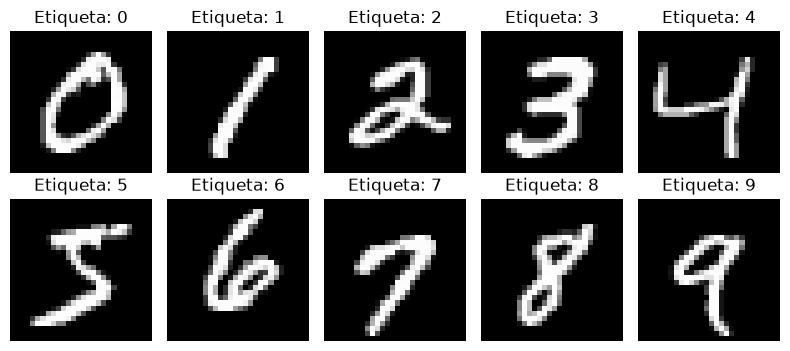

In [2]:

# Carga MNIST (viene incluido en Keras)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print('Entrenamiento:', x_train.shape, y_train.shape)
print('Prueba:', x_test.shape, y_test.shape)
print('Valores de los píxeles: de', x_train.min(), 'a', x_train.max())
print('Imágenes de entrenamiento por dígito:', np.bincount(y_train))

# Muestra 10 ejemplos (uno de cada dígito) con su etiqueta
figura, ejes = plt.subplots(2, 5, figsize=(8, 3.6))
for digito, eje in enumerate(ejes.ravel()):
    indice = np.where(y_train == digito)[0][0]
    eje.imshow(x_train[indice], cmap='gray')
    eje.set_title(f'Etiqueta: {digito}')
    eje.axis('off')
plt.tight_layout()
plt.show()

## 3. Modelo

Se usa una red neuronal densa (perceptrón multicapa):

- **Rescaling:** pasa los píxeles de 0-255 a 0-1, porque la red aprende mejor con valores pequeños. Va dentro del modelo, así la aplicación no tiene que normalizar nada.
- **Flatten:** convierte la imagen de 28 × 28 en una lista de 784 números.
- **Dense 512 y Dense 256 (ReLU):** capas ocultas que aprenden los rasgos de cada dígito.
- **Dropout 0.3:** en cada paso de entrenamiento apaga al azar el 30 % de las neuronas de esa capa, para que el modelo no memorice los ejemplos (sobreajuste).
- **Dense 10 (softmax):** una salida por dígito, con la probabilidad de que la imagen sea ese dígito.

In [3]:

modelo = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Rescaling(1.0 / 255),              # píxeles de 0-255 a 0-1
    layers.Flatten(),                          # imagen 28x28 a vector de 784
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.3),                       # evita que memorice los datos
    layers.Dense(256, activation='relu'),
    layers.Dense(10, activation='softmax'),    # probabilidad de cada dígito
])

modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Entrenamiento

- **Optimizador Adam:** ajusta los pesos de la red de forma automática.
- **Pérdida `sparse_categorical_crossentropy`:** mide qué tan lejos quedó la probabilidad que dio el modelo de la respuesta correcta. Se usa esta versión porque las etiquetas son números del 0 al 9.
- **Hasta 15 épocas:** el modelo puede ver los 60,000 ejemplos hasta 15 veces.
- **Lotes de 64:** actualiza los pesos cada 64 imágenes.
- **`validation_split=0.1`:** aparta el 10 % de los datos de entrenamiento para revisar, época por época, si el modelo también acierta con imágenes que no usó para aprender.
- **`EarlyStopping`:** detiene el entrenamiento si la pérdida de validación no mejora en 3 épocas seguidas, y se queda con los mejores pesos. Así no se entrena de más.

In [4]:

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

parada_temprana = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

historial = modelo.fit(
    x_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    callbacks=[parada_temprana],
    verbose=2,
)

print('Épocas realizadas:', len(historial.history['loss']))

Epoch 1/15
844/844 - 6s - 7ms/step - accuracy: 0.9257 - loss: 0.2478 - val_accuracy: 0.9725 - val_loss: 0.1009
Epoch 2/15
844/844 - 5s - 6ms/step - accuracy: 0.9655 - loss: 0.1123 - val_accuracy: 0.9763 - val_loss: 0.0808
Epoch 3/15
844/844 - 5s - 5ms/step - accuracy: 0.9738 - loss: 0.0830 - val_accuracy: 0.9795 - val_loss: 0.0683
Epoch 4/15
844/844 - 5s - 5ms/step - accuracy: 0.9791 - loss: 0.0651 - val_accuracy: 0.9787 - val_loss: 0.0747
Epoch 5/15
844/844 - 5s - 5ms/step - accuracy: 0.9825 - loss: 0.0556 - val_accuracy: 0.9808 - val_loss: 0.0733
Epoch 6/15
844/844 - 5s - 5ms/step - accuracy: 0.9837 - loss: 0.0507 - val_accuracy: 0.9807 - val_loss: 0.0696
Épocas realizadas: 6


## 5. Resultados

Las gráficas muestran cómo fue mejorando el modelo en cada época. Si la curva de validación se separa mucho de la de entrenamiento, el modelo se está sobreajustando.

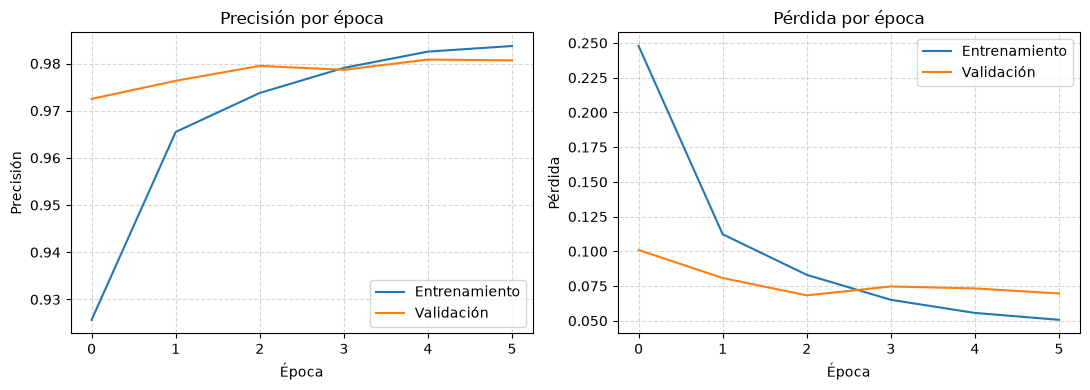

In [5]:

figura, (eje1, eje2) = plt.subplots(1, 2, figsize=(11, 4))

eje1.plot(historial.history['accuracy'], label='Entrenamiento')
eje1.plot(historial.history['val_accuracy'], label='Validación')
eje1.set_title('Precisión por época')
eje1.set_xlabel('Época')
eje1.set_ylabel('Precisión')
eje1.legend()
eje1.grid(True, linestyle='--', alpha=0.5)

eje2.plot(historial.history['loss'], label='Entrenamiento')
eje2.plot(historial.history['val_loss'], label='Validación')
eje2.set_title('Pérdida por época')
eje2.set_xlabel('Época')
eje2.set_ylabel('Pérdida')
eje2.legend()
eje2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [6]:

# Prueba final con las 10,000 imágenes que el modelo nunca vio
perdida, precision = modelo.evaluate(x_test, y_test, verbose=0)
print(f'Precisión en prueba: {precision:.2%}')
print(f'Pérdida en prueba:   {perdida:.4f}')

Precisión en prueba: 97.88%
Pérdida en prueba:   0.0693


### Matriz de confusión

Cada fila es el dígito real y cada columna lo que predijo el modelo. Lo ideal es que todo quede en la diagonal. Los números fuera de la diagonal son errores.

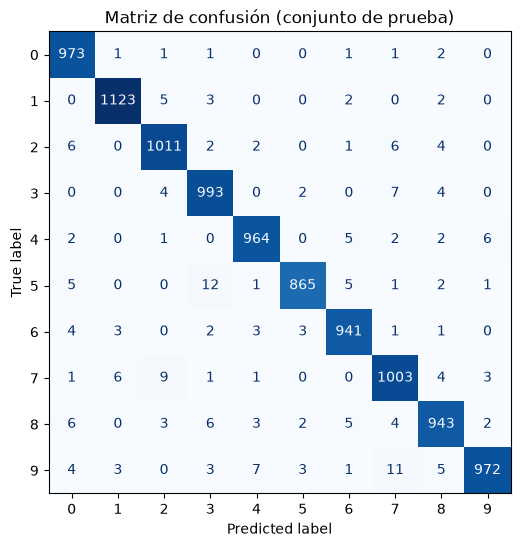

In [7]:

probabilidades = modelo.predict(x_test, verbose=0)
predicciones = np.argmax(probabilidades, axis=1)

matriz = confusion_matrix(y_test, predicciones)
figura, eje = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(matriz, display_labels=range(10)).plot(ax=eje, cmap='Blues', colorbar=False)
eje.set_title('Matriz de confusión (conjunto de prueba)')
plt.show()

### Ejemplos de predicciones y de errores

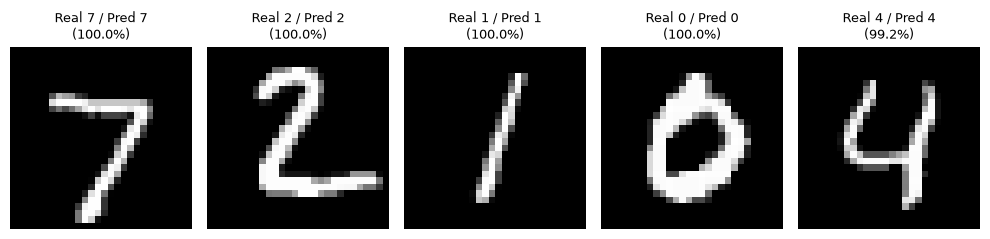

Imágenes mal clasificadas: 212 de 10000


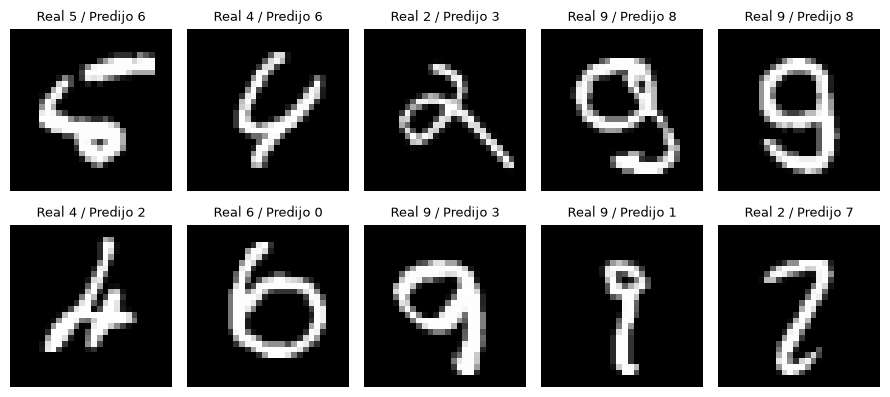

In [8]:

# 1) Cinco imágenes de prueba con lo que predijo el modelo y su seguridad
figura, ejes = plt.subplots(1, 5, figsize=(10, 2.6))
for eje, i in zip(ejes, range(5)):
    eje.imshow(x_test[i], cmap='gray')
    eje.set_title(f'Real {y_test[i]} / Pred {predicciones[i]}\n({probabilidades[i].max():.1%})', fontsize=9)
    eje.axis('off')
plt.tight_layout()
plt.show()

# 2) Algunos errores del modelo
errores = np.where(predicciones != y_test)[0]
print('Imágenes mal clasificadas:', len(errores), 'de', len(y_test))

figura, ejes = plt.subplots(2, 5, figsize=(9, 4.2))
for eje, i in zip(ejes.ravel(), errores[:10]):
    eje.imshow(x_test[i], cmap='gray')
    eje.set_title(f'Real {y_test[i]} / Predijo {predicciones[i]}', fontsize=9)
    eje.axis('off')
plt.tight_layout()
plt.show()

## 6. Guardar el modelo

El modelo se guarda en un solo archivo `.keras` que ya incluye la arquitectura y los pesos entrenados. Ese archivo es el que carga la aplicación `tarea7_mnist_probar.py`. Después se vuelve a cargar aquí mismo para comprobar que se guardó bien: debe dar exactamente las mismas predicciones.

In [9]:

modelo.save('modelo_digitos.keras')
print('Modelo guardado como modelo_digitos.keras')

# Comprobación: cargarlo de nuevo y comparar predicciones
modelo_cargado = keras.models.load_model('modelo_digitos.keras')
predicciones_cargado = np.argmax(modelo_cargado.predict(x_test, verbose=0), axis=1)
print('El modelo cargado da las mismas predicciones:', np.array_equal(predicciones, predicciones_cargado))

# En Colab lo descarga a la computadora
try:
    from google.colab import files
    files.download('modelo_digitos.keras')
except ImportError:
    print('No estoy en Colab, el archivo quedó en la carpeta actual')

Modelo guardado como modelo_digitos.keras
El modelo cargado da las mismas predicciones: True
No estoy en Colab, el archivo quedó en la carpeta actual


## Conclusiones

In [10]:

# Resumen con los números de esta ejecución
acierto_por_digito = matriz.diagonal() / matriz.sum(axis=1)
mejor = int(np.argmax(acierto_por_digito))
peor = int(np.argmin(acierto_por_digito))
pares = [(int(matriz[r, c]), r, c) for r in range(10) for c in range(10) if r != c]
n_conf, real, pred = max(pares)

print(f'El modelo acertó el {precision:.2%} de las 10,000 imágenes de prueba.')
print(f'El dígito que mejor reconoce es el {mejor} ({acierto_por_digito[mejor]:.2%}) y el que más se le dificulta es el {peor} ({acierto_por_digito[peor]:.2%}).')
print(f'La confusión más común es tomar un {real} por un {pred} ({n_conf} veces).')
epoca_final = len(historial.history['loss'])
print(f'El entrenamiento se detuvo en la época {epoca_final} de 15 (precisión final: '
      f'{historial.history["accuracy"][-1]:.2%} en entrenamiento y {historial.history["val_accuracy"][-1]:.2%} en validación).')

El modelo acertó el 97.88% de las 10,000 imágenes de prueba.
El dígito que mejor reconoce es el 0 (99.29%) y el que más se le dificulta es el 9 (96.33%).
La confusión más común es tomar un 5 por un 3 (12 veces).
El entrenamiento se detuvo en la época 6 de 15 (precisión final: 98.37% en entrenamiento y 98.07% en validación).


Una red densa sencilla logra una precisión alta en MNIST. Aun así comete errores con dígitos de trazo parecido, como se ve en la matriz de confusión.

Lo importante para la aplicación es que el archivo `modelo_digitos.keras` ya contiene todo lo aprendido: arquitectura, pesos y la normalización de los píxeles. Por eso `tarea7_mnist_probar.py` puede cargarlo y usarlo sin volver a entrenar.